# Customer Segmentation Project using KMeans Clustering


### _- A Project by Om Satyawan Pathak_



In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import warnings

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

## 1. Load the dataset

In [2]:
import pandas as pd

df = pd.read_csv("Mall_Customers.csv")

print("\nDataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Dataset loaded successfully!
Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 2. Dataset Information

In [3]:
print('Shape:', df.shape)
print('\nColumns:')
print(df.columns.tolist())
print('\nData Types:')
print(df.dtypes)
print('\nMissing Values:')
print(df.isnull().sum())
print('\nDuplicate Rows:', df.duplicated().sum())

Shape: (200, 5)

Columns:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Data Types:
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate Rows: 0


In [4]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


## 3. Exploratory Data Analysis

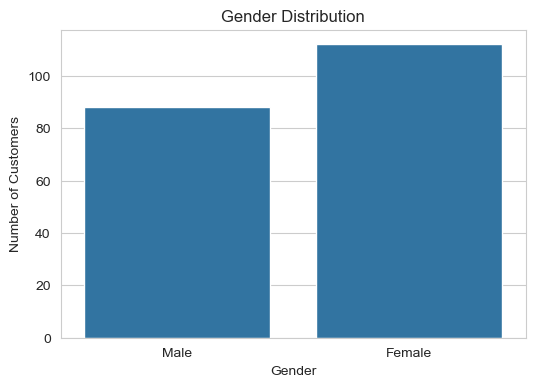

In [5]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Gender')
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.show()

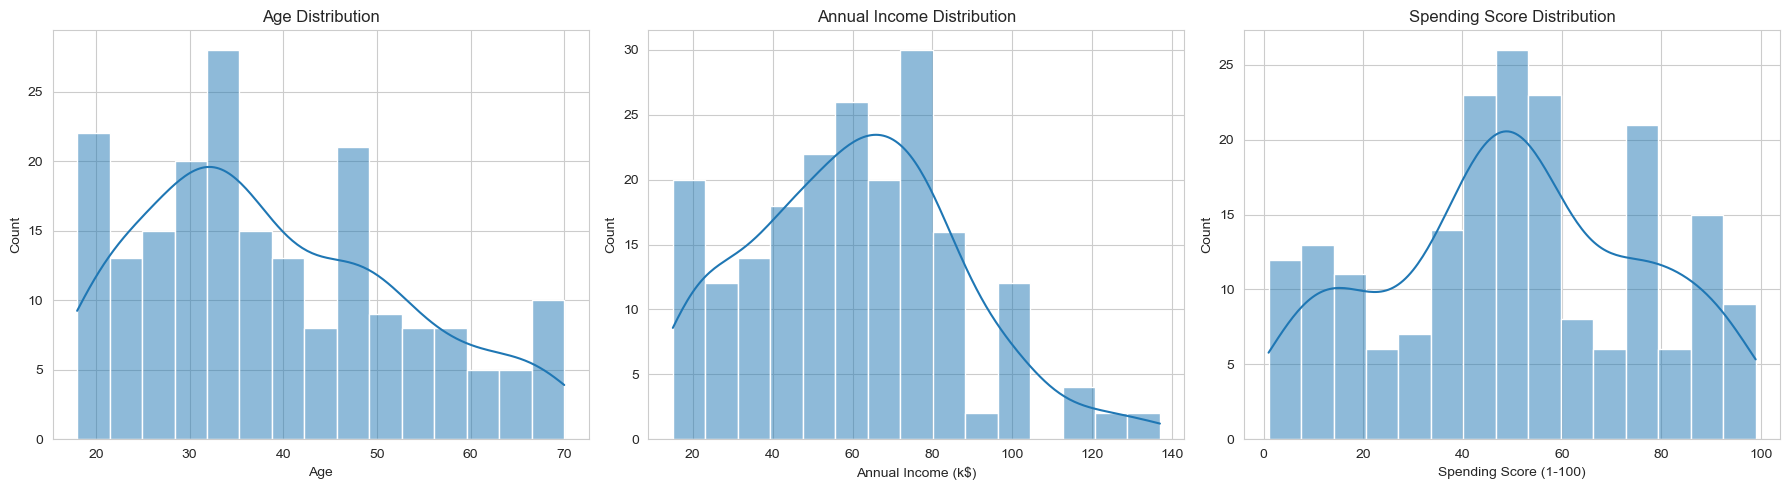

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18,5))

sns.histplot(df['Age'], bins=15, kde=True, ax=axes[0])
axes[0].set_title('Age Distribution')

sns.histplot(df['Annual Income (k$)'], bins=15, kde=True, ax=axes[1])
axes[1].set_title('Annual Income Distribution')

sns.histplot(df['Spending Score (1-100)'], bins=15, kde=True, ax=axes[2])
axes[2].set_title('Spending Score Distribution')

plt.tight_layout()
plt.show()

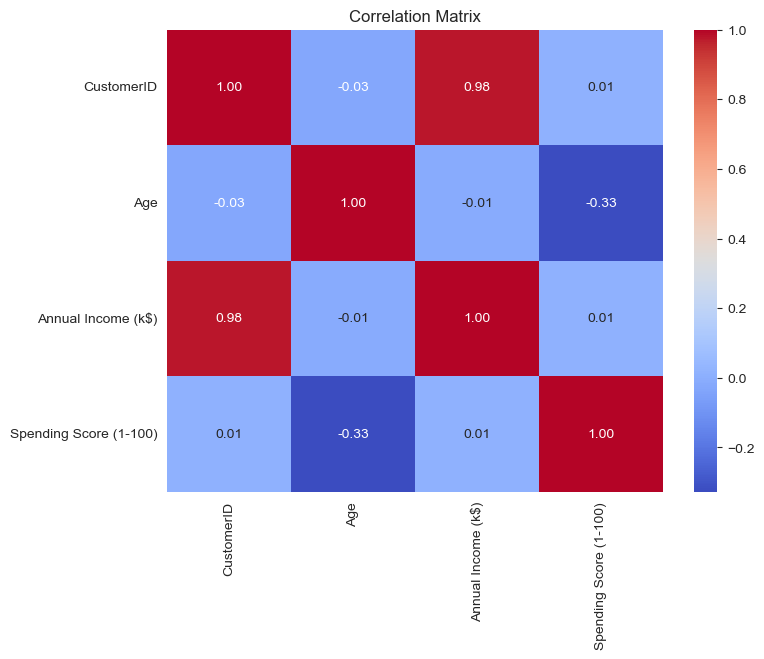

In [7]:
plt.figure(figsize=(8,6))
sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)
plt.title('Correlation Matrix')
plt.show()

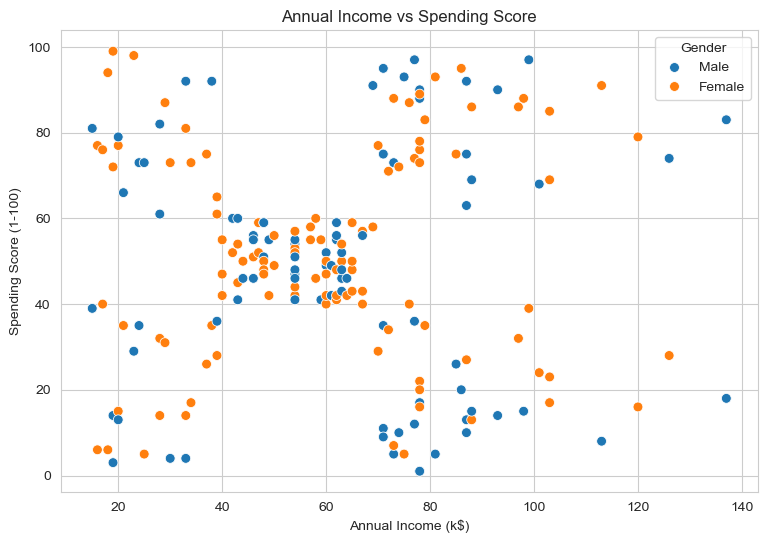

In [8]:
plt.figure(figsize=(9,6))
sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Gender',
    s=50
)
plt.title('Annual Income vs Spending Score')
plt.show()

## 4. Feature Selection

We use **Annual Income** and **Spending Score** for customer segmentation.

In [9]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print('Feature matrix shape:', X.shape)

Feature matrix shape: (200, 2)


## 5. Elbow Method and Silhoutte Score:

For K = 2 ----> Silhouette Score = 0.32127
For K = 3 ----> Silhouette Score = 0.46658
For K = 4 ----> Silhouette Score = 0.49391
For K = 5 ----> Silhouette Score = 0.55466
For K = 6 ----> Silhouette Score = 0.53988
For K = 7 ----> Silhouette Score = 0.52815
For K = 8 ----> Silhouette Score = 0.45521
For K = 9 ----> Silhouette Score = 0.45709
For K = 10 ----> Silhouette Score = 0.44317


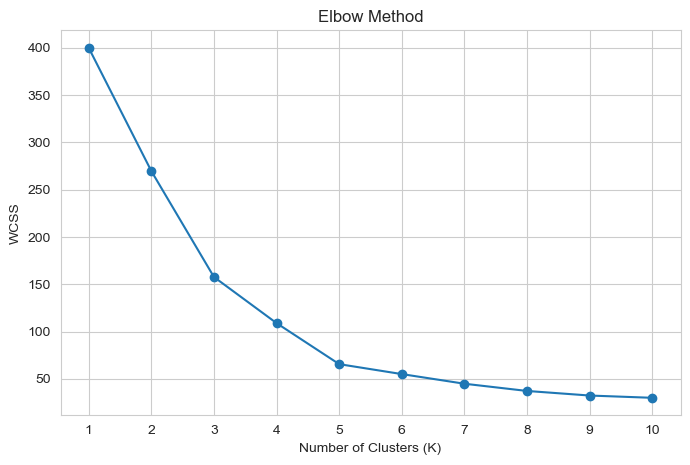

In [10]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(X_scaled)

    wcss.append(kmeans.inertia_)

    if k >= 2:
        score = silhouette_score(X_scaled, labels)
        print(f"For K = {k} ----> Silhouette Score = {score:.5f}")
    
    

plt.figure(figsize=(8,5))
plt.plot(range(1,11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(range(1,11))
plt.show()

## 6. K-Means Clustering with K = 5

In [11]:
kmeans = KMeans(
    n_clusters=5,
    init='k-means++',
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)
df.head(10)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2


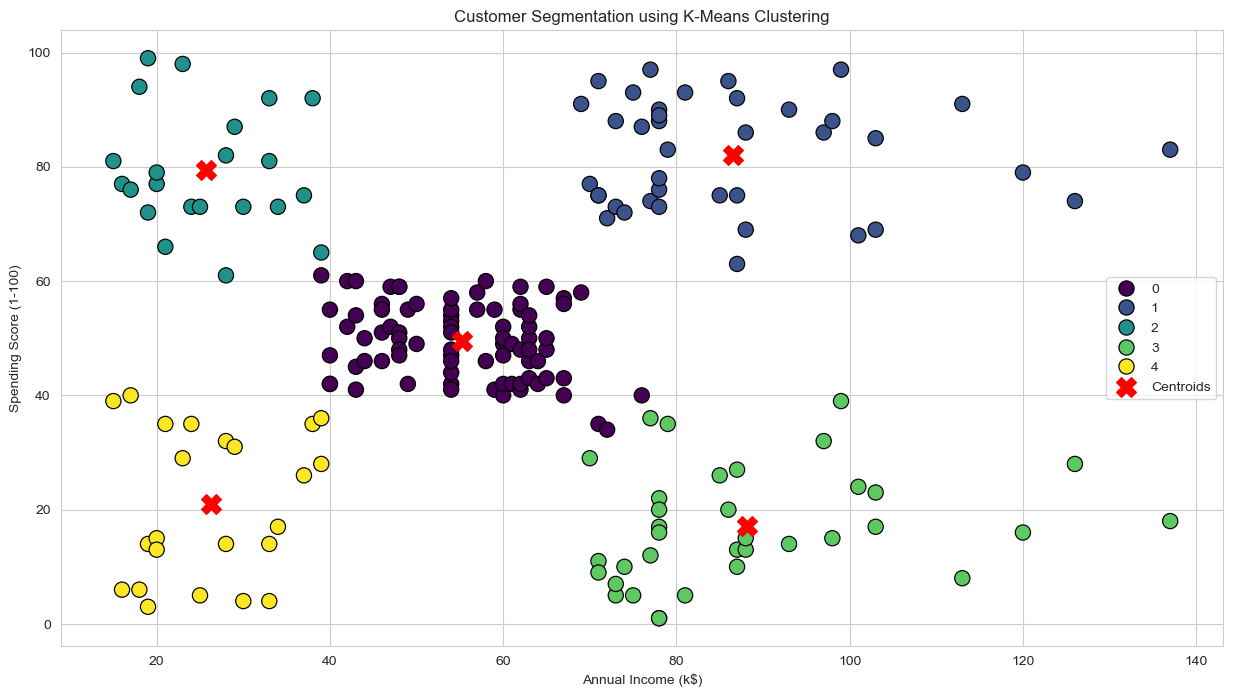

In [12]:
plt.figure(figsize=(15,8))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='viridis',
    edgecolors='black',
    s=120
)

centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    s=200,
    marker='X',
    c='red',
    label='Centroids'
)

plt.title('Customer Segmentation using K-Means Clustering')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()

## 7. Cluster Summary

In [13]:
cluster_summary = df.groupby('Cluster').agg(
    Customers=('CustomerID', 'count'),
    Average_Age=('Age', 'mean'),
    Average_Income=('Annual Income (k$)', 'mean'),
    Average_Spending=('Spending Score (1-100)', 'mean')
).round()

cluster_summary

,Customers,Average_Age,Average_Income,Average_Spending
Cluster,,,,
0,81,43.0,55.0,50.0
1,39,33.0,87.0,82.0
2,22,25.0,26.0,79.0
3,35,41.0,88.0,17.0
4,23,45.0,26.0,21.0


## 8. Silhouette Score

In [14]:
silhouette = silhouette_score(X_scaled, df['Cluster'])
print('Silhouette Score:', round(silhouette, 5))

Silhouette Score: 0.55466


## 9. Customers in Each Cluster

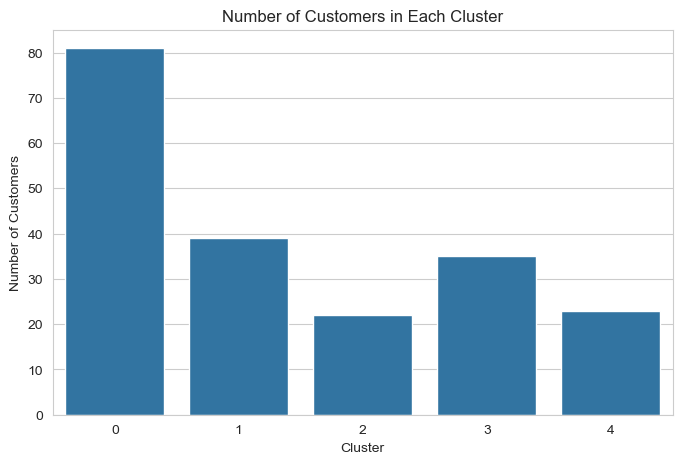

In [15]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Cluster')
plt.title('Number of Customers in Each Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')
plt.show()

## 10. Conclusion

### Business Insights from Customer Segmentation

The K-Means clustering algorithm identified five distinct customer segments based on their income and spending behavior. The model achieved a Silhouette Score of **0.55466**, indicating reasonably good separation between the clusters. The results provide useful insights for developing targeted marketing strategies, improving customer engagement, and identifying opportunities to increase sales.

**Cluster 0 – Moderate-Income, Moderate-Spending Customers:** This is the largest cluster, containing 81 customers with an average age of 43 years, an average annual income of approximately $55k, and an average spending score of 50. These customers demonstrate moderate spending behavior and represent a substantial portion of the customer base. Businesses can target this segment with seasonal promotions, product recommendations, cross-selling opportunities, and loyalty programs to encourage additional purchases.

**Cluster 1 – High-Income, High-Spending Customers:** This cluster consists of 39 customers with an average age of 33 years, an average annual income of approximately $87k, and an average spending score of 82. These relatively younger customers have high incomes and high spending scores, making them a valuable segment for premium products, exclusive offers, personalized shopping experiences, and customer retention programs.

**Cluster 2 – Low-Income, High-Spending Customers:** This cluster contains 22 customers with an average age of 25 years, an average annual income of approximately $26k, and an average spending score of 79. These customers are relatively young and spend considerably despite their lower average incomes. Businesses can attract and retain them through affordable trendy products, flexible offers, student or youth-oriented promotions, and personalized recommendations while remaining mindful of their budget constraints.

**Cluster 3 – High-Income, Low-Spending Customers:** This cluster contains 35 customers with an average age of 41 years, an average annual income of approximately $88k, and an average spending score of 17. Although these customers earn relatively high incomes, their spending activity is low. Businesses could investigate the reasons for their limited purchases and use targeted promotions, personalized recommendations, loyalty incentives, and premium product demonstrations to encourage greater engagement.

**Cluster 4 – Low-Income, Low-Spending Customers:** This cluster consists of 23 customers with an average age of 45 years, an average annual income of approximately $26k, and an average spending score of 21. These customers have relatively low incomes and low spending activity. Businesses can focus on affordable products, budget-friendly offers, discounts, and essential product recommendations to meet their needs without relying on expensive promotional strategies.

**Overall Conclusion:** The analysis demonstrates that customers have different demographic characteristics, income levels, and spending patterns and should not be treated as a single homogeneous group. The five segments enable businesses to distinguish between high-value customers, customers with potential for increased spending, and customers who may respond better to budget-friendly offerings. By tailoring marketing campaigns, pricing strategies, and product recommendations to each segment, businesses can allocate marketing resources more effectively, strengthen customer relationships, improve customer retention, and identify opportunities for revenue growth. The Silhouette Score of 0.55466 supports the usefulness of this clustering solution, although the final choice of five clusters should also consider the interpretability and practical business value of the resulting segments.

In [16]:
df.to_csv('ALL_customer_segments.csv', index=False)
print('Saved segmented dataset to ALL_customer_segments.csv')

Saved segmented dataset to ALL_customer_segments.csv
